# Reproducing GRAHSP's AGN physics with tengri

GRAHSP (Buchner et al. 2024, A&A 692, A161; arXiv:2405.19297) fits galaxy spectra with an AGN
model built from a smooth big-blue bump, emission lines and a FeII forest, an infrared torus
with a silicate feature, and bi-attenuation. Its authors released the model as pcigale
modules. This page compares tengri's GRAHSP components with upstream GRAHSP's own spectra,
one component at a time and then in full.

Upstream's spectra are committed in `data/grahsp_upstream_reference.h5`: 38 parameter sets
(a fiducial plus one-at-a-time sweeps), each evaluated by upstream's code at unit
normalization. The page never imports upstream GRAHSP. tengri implements the same physics
independently, and the comparison is the validation.

**Reading guide.** Each figure prints the largest disagreement it shows, as max |log10 ratio|
in dex over the points both codes define. Upstream's torus is tabulated on its own template
nodes, and its lines are sampled on nine nodes per line, so those two components are compared
on upstream's nodes. Sections 3.1 to 3.3 apply the upstream errors that the reference file can
test, to upstream's values, and section 3.5 states the three it cannot.

| Component | tengri | Agreement, all sets (max \|Δ\|, dex) | Section |
|---|---|---|---|
| Big blue bump (smooth bending power law) | `grahsp_sbpl` | 5.3e-16 | 1, 2 |
| Broad and narrow emission lines | `grahsp` (blr, nlr) | 6.7e-7 after the √2 correction | 1, 2, 3.1 |
| FeII forest | `grahsp` (feii) | 1.1e-12 | 1, 2 |
| Torus (log-Gaussian) and Si feature | `grahsp` (torus, Si) | 2.5e-15 torus, 6.1e-15 Si, after the width correction | 1, 2, 3.2 |
| Balmer continuum | `grahsp` (feii side) | 9.5e-4 integral over 210–355 nm (smoothing differs) | 3.3 |
| Full composite | `evaluate_grahsp_agn` | 4.0e-8 (fiducial), 2.2e-8 (type 2) | 4 |

## Setup

The reference file is committed, so the page runs on a clean checkout. The driver reads it
and nothing else. The menus below come from the installed registry, not from a list kept
in the text.

In [1]:
import dataclasses
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

from reproduction.grahsp._drivers import grahsp_driver as G

# Inline backend, so every figure embeds in the rendered page.
try:  # noqa: SIM105
    get_ipython().run_line_magic("matplotlib", "inline")
except NameError:
    pass

import tengri

warnings.filterwarnings("ignore")
warnings.filterwarnings("default", module=r"tengri(\.|$)")
tengri.plot.setup_style()

_HERE = Path(__file__).resolve().parent if "__file__" in dir() else Path.cwd().resolve()
FIGS = _HERE / "_figs"
FIGS.mkdir(exist_ok=True)


def save_fig(filename: str) -> None:
    """Write the current figure into ``_figs/`` and leave it open for the page."""
    plt.savefig(str(FIGS / filename), dpi=150, bbox_inches="tight")


G.require_available()
SETS = G.list_param_sets()
print(f"upstream GRAHSP reference: {len(SETS)} parameter sets, file {G.REFERENCE_PATH.name}")
print("live menus (installed registry):")
for _cat in ("disc", "torus", "feii", "blr", "nlr"):
    _names = sorted(r["name"] for r in tengri.list_agn_blocks(category=_cat) if "grahsp" in r["name"])
    print(f"  tengri.list_agn_blocks(category={_cat!r}), GRAHSP entries: {_names}")

upstream GRAHSP reference: 38 parameter sets, file grahsp_upstream_reference.h5
live menus (installed registry):
  tengri.list_agn_blocks(category='disc'), GRAHSP entries: ['grahsp_netzer', 'grahsp_sbpl']
  tengri.list_agn_blocks(category='torus'), GRAHSP entries: ['grahsp', 'grahsp_mn12']
  tengri.list_agn_blocks(category='feii'), GRAHSP entries: ['grahsp', 'grahsp_veroncetty']
  tengri.list_agn_blocks(category='blr'), GRAHSP entries: ['grahsp']
  tengri.list_agn_blocks(category='nlr'), GRAHSP entries: ['grahsp']


## 1. Fiducial components, side by side

The fiducial is upstream's default: power-law slope -1.7, bend at 100 nm, `fcov = 0.4`, a
Bruhweiler & Verner (2008) FeII template, and a type-1 AGN with 5000 km/s lines. Upstream is
in `C0` and tengri in `C1`, on upstream's own support. The disc is compared above 12.4 nm,
where tengri's disc is defined (section 3.4 explains the floor). The torus is compared
between 0.4 and 99 μm, and the lines on upstream's line nodes.

§1 big blue bump          max|Δ| = 3.86e-16 dex over 3861 points
§1 torus (log-Gaussian)   max|Δ| = 9.64e-16 dex over 2393 points
§1 Si feature             max|Δ| = 6.08e-15 dex over 654 points
§1 FeII forest            max|Δ| = 1.06e-12 dex over 543 points


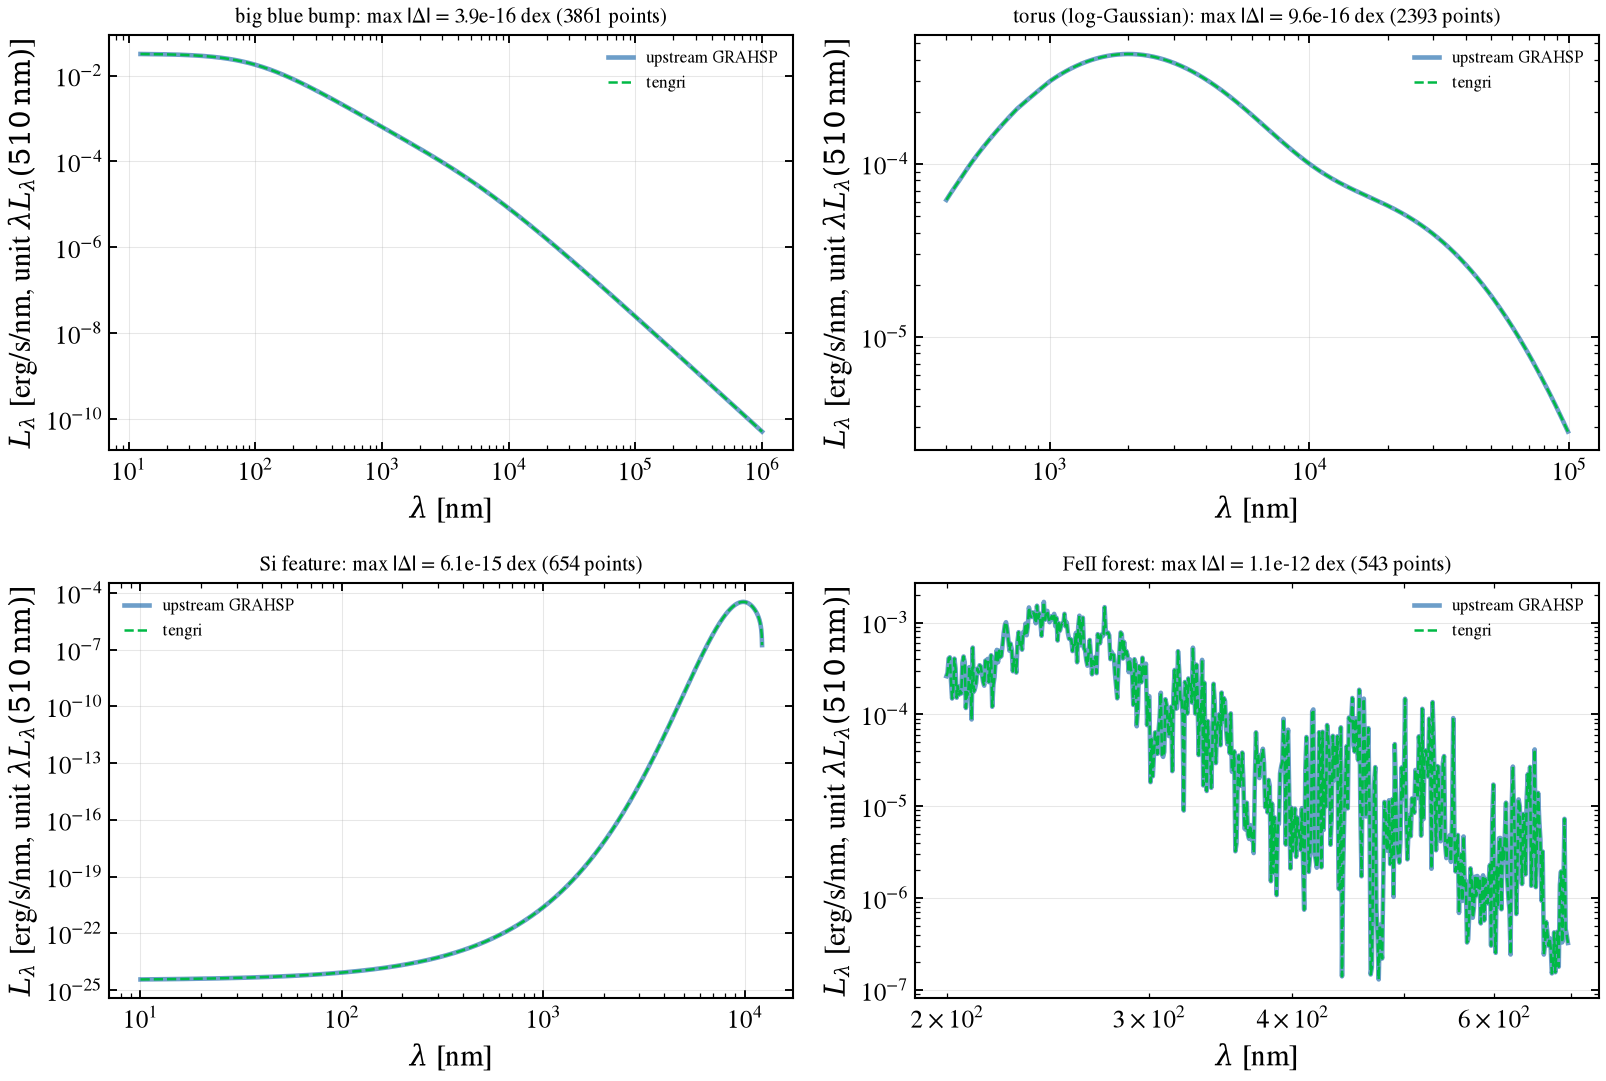

In [2]:
_fid = G.load_set("fiducial")
_p_fid = G.tengri_params(_fid.params)
_sed_fid = G.evaluate(_fid.wave_nm, _p_fid)
_nodes_fid, _bl_nodes, _nl_nodes = G.line_nodes_and_values(_p_fid)
_torus_nodes, _torus_node_L = G.torus_on_upstream_nodes(_p_fid)

_disc_t = np.asarray(_sed_fid.bbb)
_feii_t = np.asarray(_sed_fid.feii)
_si_t = np.asarray(_sed_fid.si)
_torus_t_grid = np.interp(_fid.wave_nm, _torus_nodes, _torus_node_L, left=0.0, right=0.0)
_bl_t_grid = np.interp(_fid.wave_nm, _nodes_fid, _bl_nodes * G.LINE_FLUX_SCALE, left=0.0, right=0.0)
_nl_t_grid = np.interp(_fid.wave_nm, _nodes_fid, _nl_nodes * G.LINE_FLUX_SCALE, left=0.0, right=0.0)

_panels = [
    ("big blue bump", _fid.spectra["disc"], _disc_t, G.upstream_window_mask(_fid.wave_nm, "disc")),
    ("torus (log-Gaussian)", _fid.spectra["torus"], _torus_t_grid, G.upstream_window_mask(_fid.wave_nm, "torus")),
    ("Si feature", _fid.spectra["si"], _si_t, np.ones_like(_fid.wave_nm, bool)),
    ("FeII forest", _fid.spectra["feii"], _feii_t, np.ones_like(_fid.wave_nm, bool)),
]
fig, axes = plt.subplots(2, 2, figsize=(11, 7.5))
for ax, (title, up, tg, win) in zip(axes.ravel(), _panels):
    m = win & (up > 0) & (np.abs(tg) > 0)
    ax.loglog(_fid.wave_nm[m], up[m], "C0-", lw=2.2, alpha=0.6, label="upstream GRAHSP")
    ax.loglog(_fid.wave_nm[m], tg[m], "C1--", lw=1.2, label="tengri")
    _n, _dex = G.dex_error(tg, up, win)
    ax.set_title(f"{title}: max |Δ| = {_dex:.1e} dex ({_n} points)", fontsize=10)
    ax.set_xlabel(r"$\lambda$ [nm]")
    ax.set_ylabel(r"$L_\lambda$ [erg/s/nm, unit $\lambda L_\lambda(510\,\mathrm{nm})$]")
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=8)
    print(f"§1 {title:22s} max|Δ| = {_dex:.2e} dex over {_n} points")
fig.tight_layout()
save_fig("grahsp_01_fiducial_components.png")

§1 lines broad (type 1)     max|Δ| = 5.11e-07 dex over 521 points (after the √2 factor)
§1 lines narrow             max|Δ| = 4.64e-07 dex over 609 points (after the √2 factor)


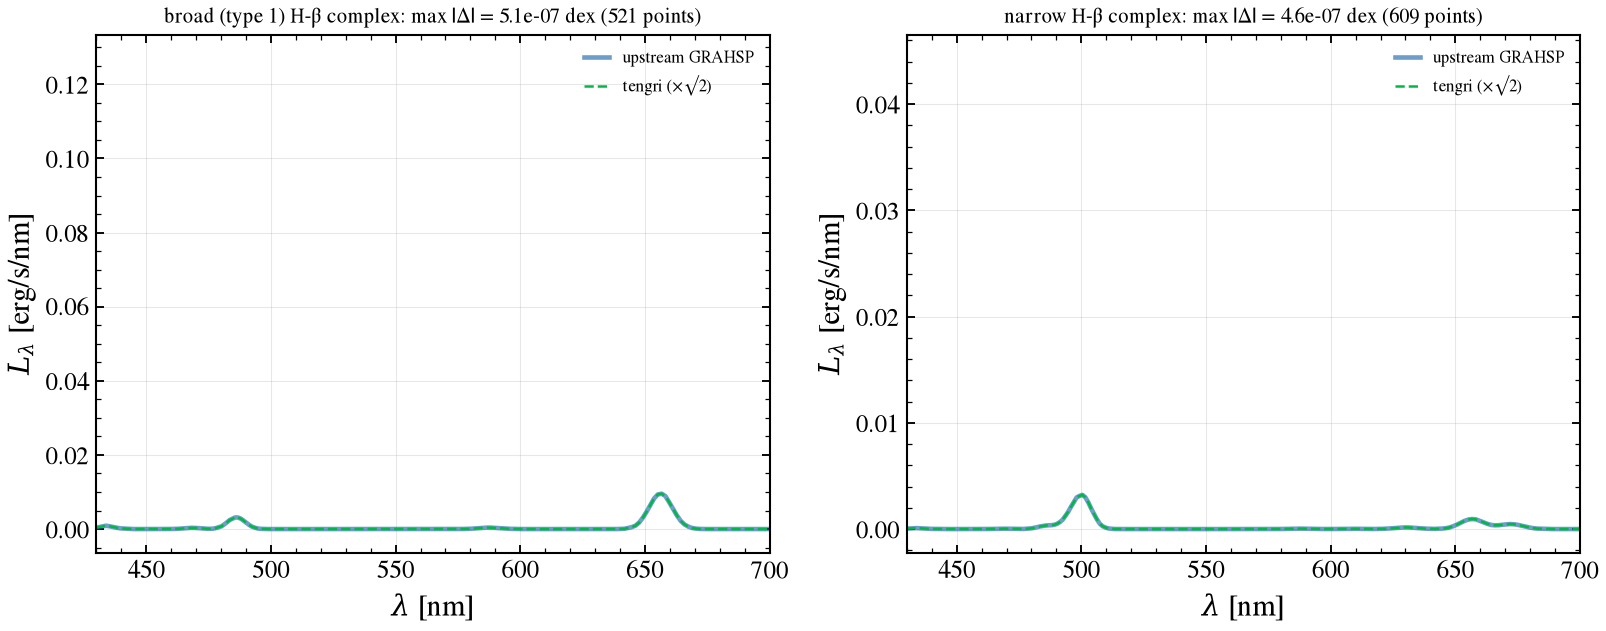

In [3]:
_lines_win = np.ones_like(_nodes_fid, dtype=bool)
fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, key, tg_nodes, lab in (
    (ax0, "bl", _bl_nodes, "broad (type 1)"),
    (ax1, "nl", _nl_nodes, "narrow"),
):
    up_grid = _fid.spectra[key]
    n, dex = G.dex_error(
        np.interp(_fid.wave_nm, _nodes_fid, tg_nodes * G.LINE_FLUX_SCALE, left=0.0, right=0.0),
        up_grid,
        np.ones_like(_fid.wave_nm, bool),
    )
    m = up_grid > 0
    ax.plot(_fid.wave_nm[m], up_grid[m], "C0-", lw=2.2, alpha=0.6, label="upstream GRAHSP")
    ax.plot(
        _fid.wave_nm[m],
        np.interp(_fid.wave_nm, _nodes_fid, tg_nodes * G.LINE_FLUX_SCALE, left=0.0, right=0.0)[m],
        "C1--", lw=1.2, label="tengri (×√2)",
    )
    ax.set_xlim(430, 700)
    ax.set_title(f"{lab} H-β complex: max |Δ| = {dex:.1e} dex ({n} points)", fontsize=10)
    ax.set_xlabel(r"$\lambda$ [nm]")
    ax.set_ylabel(r"$L_\lambda$ [erg/s/nm]")
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=8)
    print(f"§1 lines {lab:18s} max|Δ| = {dex:.2e} dex over {n} points (after the √2 factor)")
fig.tight_layout()
save_fig("grahsp_02_lines_corrected.png")

**Result.** The disc, FeII forest and Si feature agree with upstream to 10⁻¹² dex or better
on the printed points. The torus agrees to 10⁻¹⁵ dex, and the lines to 5×10⁻⁷ dex, only after
the width and √2 corrections of section 3. Both components are interpolated from upstream's
nodes, the basis upstream itself uses. Evaluating them directly on the 5000-point grid would
compare interpolation error, not physics.

## 2. Agreement across all 38 parameter sets

Each set is evaluated with the same comparison rules as above. A component that is zero in
upstream must also be zero in tengri, and a component active in upstream is compared on its
own support. The table gives the largest disagreement over all sets in which the component
is active. Sets in which it is switched off are counted as agreeing when both codes are zero.

In [4]:
def _set_agreement(name):
    s = G.load_set(name)
    p = G.tengri_params(s.params)
    sed = G.evaluate(s.wave_nm, p)
    out = {}
    up_type1 = s.params["type"] == 1
    # Disc above the X-ray floor.
    out["big blue bump"] = G.dex_error(np.asarray(sed.bbb), s.spectra["disc"], G.upstream_window_mask(s.wave_nm, "disc"))
    # FeII forest, active for type 1 with afeii > 0.
    out["FeII forest"] = G.dex_error(np.asarray(sed.feii), s.spectra["feii"], np.ones_like(s.wave_nm, bool))
    # Si feature (on the grid).
    out["Si feature"] = G.dex_error(np.asarray(sed.si), s.spectra["si"], np.ones_like(s.wave_nm, bool))
    # Torus on nodes, inside 0.4-99 micron.
    nodes, tnode = G.torus_on_upstream_nodes(p)
    tg = np.interp(s.wave_nm, nodes, tnode, left=0.0, right=0.0)
    out["torus"] = G.dex_error(tg, s.spectra["torus"], G.upstream_window_mask(s.wave_nm, "torus"))
    # Lines on upstream's nodes, after the sqrt(2) factor.
    nodes_l, bl, nl = G.line_nodes_and_values(p)
    if up_type1:
        out["broad lines"] = G.dex_error(
            np.interp(s.wave_nm, nodes_l, bl * G.LINE_FLUX_SCALE, left=0.0, right=0.0),
            s.spectra["bl"],
            np.ones_like(s.wave_nm, bool),
        )
    out["narrow lines"] = G.dex_error(
        np.interp(s.wave_nm, nodes_l, nl * G.LINE_FLUX_SCALE, left=0.0, right=0.0),
        s.spectra["nl"],
        np.ones_like(s.wave_nm, bool),
    )
    return out


_agree = {}
for _name in SETS:
    _agree[_name] = _set_agreement(_name)
_comps = ["big blue bump", "FeII forest", "Si feature", "torus", "broad lines", "narrow lines"]
print(f"{'component':16s} {'sets active':>12s} {'max |Δ| (dex)':>16s} {'worst set':>26s}")
for _c in _comps:
    _vals = [(n, _agree[n][_c][1]) for n in SETS if _c in _agree[n] and _agree[n][_c][0] > 0]
    _worst = max(_vals, key=lambda t: t[1])
    print(f"{_c:16s} {len(_vals):12d} {_worst[1]:16.2e} {_worst[0]:>26s}")

component         sets active    max |Δ| (dex)                  worst set
big blue bump              38         5.30e-16              plslope_-1_p0
FeII forest                36         1.06e-12                    afeii_2
Si feature                 37         6.08e-15                   abc_0_p3
torus                      38         2.46e-15            coolwidth_0_p35
broad lines                37         6.66e-07         linewidth_10000_p0
narrow lines               38         6.39e-07         linewidth_10000_p0


**Result.** Over all sets, the disc, FeII, and Si feature agree to within 10⁻¹¹ dex. The torus
agrees to within 10⁻¹⁴ dex after the width correction in section 3.2, and the lines to within
10⁻⁶ dex after the √2 correction in section 3.1. The line residuals sit near the largest
sweep, linewidth 10000 km/s, where the lines are broadest and the node spacing is coarsest.

## 3. Where tengri deliberately differs from upstream

Sections 3.1 to 3.3 test three upstream differences in the emission-line normalization, the
torus width, and the Balmer continuum smoothing. Section 3.4 is tengri's own disc floor, and
section 3.5 tests the Netzer disc and MN12 torus, whose upstream outputs carry the 510 factor.
Each correction is stated with the paper's equation, and the comparison is shown after
applying it to upstream's values.

### 3.1 Emission-line normalization (√2)

GRAHSP sets the line-flux normalization so that the Gaussian integrates to the line
strength. Upstream's `activatelines` divides by $\sqrt{\pi\sigma^2}$, where a unit-area
Gaussian needs $\sqrt{2\pi\sigma^2}$. Every upstream line carries an extra factor
$\sqrt{2}$; the paper gives the H-β broad-line strength as 2% of $L_\lambda(5100\,\text{Å})$, and
upstream's line is 2.8%. tengri's line strength follows the paper, so the comparison multiplies
tengri's lines by $\sqrt{2}$, equivalently divides upstream by $\sqrt{2}$.

In [5]:
_bl_on_grid = np.interp(_fid.wave_nm, _nodes_fid, _bl_nodes, left=0.0, right=0.0)
_nl_on_grid = np.interp(_fid.wave_nm, _nodes_fid, _nl_nodes, left=0.0, right=0.0)
_all = np.ones_like(_fid.wave_nm, bool)
for _lab, _up, _tg in (("broad", _fid.spectra["bl"], _bl_on_grid), ("narrow", _fid.spectra["nl"], _nl_on_grid)):
    _, _dex_raw = G.dex_error(_tg, _up, _all)
    _, _dex_fix = G.dex_error(_tg * G.LINE_FLUX_SCALE, _up, _all)
    _, _dex_up = G.dex_error(_tg, _up / G.LINE_FLUX_SCALE, _all)
    print(f"§3.1 {_lab}: max |Δ| without correction = {_dex_raw:.4f} dex (log10 √2 = {np.log10(np.sqrt(2)):.4f}); "
          f"tengri x √2 = {_dex_fix:.2e} dex; upstream / √2 = {_dex_up:.2e} dex")

§3.1 broad: max |Δ| without correction = 0.1505 dex (log10 √2 = 0.1505); tengri x √2 = 5.11e-07 dex; upstream / √2 = 5.11e-07 dex
§3.1 narrow: max |Δ| without correction = 0.1505 dex (log10 √2 = 0.1505); tengri x √2 = 4.64e-07 dex; upstream / √2 = 4.64e-07 dex


**Result.** Without the correction the two lines differ by 0.1505 dex, which is log10 √2. With
it, both agree to 5×10⁻⁷ dex, the same residual as section 2.

### 3.2 Torus log-Gaussian width (the missing ½)

Upstream's cool and hot components use $\exp(-x^2/W^2)$. Eq. 2 of Buchner et al. (2024) writes
each log-Gaussian component as $\exp[-(\log\lambda-\log\lambda_0)^2/(2W^2)]$, with $W$ in dex.
The two differ by a factor of $\sqrt{2}$ in $W$. The comparison feeds tengri $W_\text{tengri} =
W_\text{upstream}/\sqrt{2}$. The figure shows the uncorrected and corrected torus for the two
cool-component widths in the sweep.

§3.2 coolwidth_0_p35: max |Δ| uncorrected = 8.069e-01 dex, corrected = 2.459e-15 dex
§3.2 coolwidth_0_p55: max |Δ| uncorrected = 3.087e-01 dex, corrected = 6.750e-16 dex


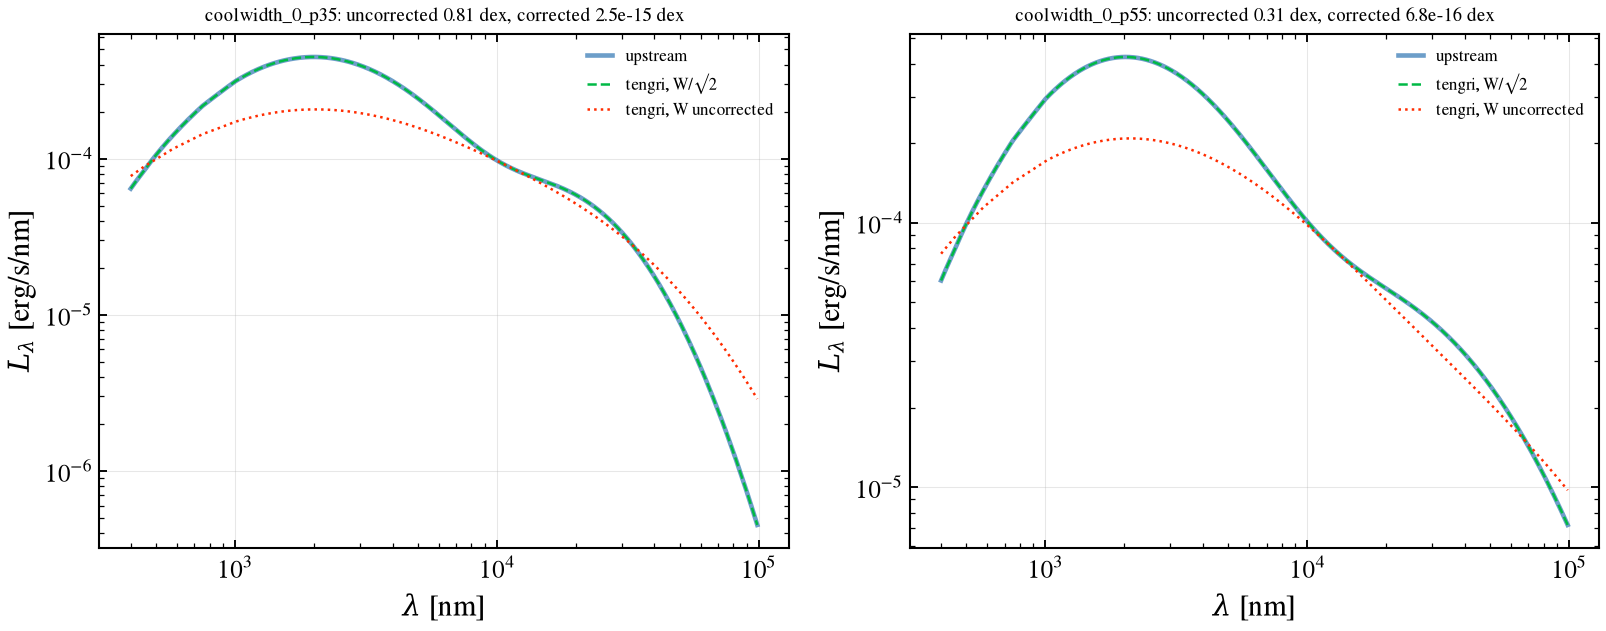

In [6]:
def _torus_on_grid(params, wave_nm):
    """tengri's torus interpolated from upstream's template nodes onto ``wave_nm``."""
    nodes, torus_nodes = G.torus_on_upstream_nodes(params)
    return np.interp(wave_nm, nodes, torus_nodes, left=0.0, right=0.0)


_fig, _axes = plt.subplots(1, 2, figsize=(11, 4.5))
_width_rows = []
for _ax, _name in zip(_axes, ("coolwidth_0_p35", "coolwidth_0_p55")):
    _s = G.load_set(_name)
    _pc = G.tengri_params(_s.params)
    _pu = G.tengri_params(_s.params, width_correction=False)
    _tc = _torus_on_grid(_pc, _s.wave_nm)
    _tu = _torus_on_grid(_pu, _s.wave_nm)
    _win = G.upstream_window_mask(_s.wave_nm, "torus")
    _, _dex_c = G.dex_error(_tc, _s.spectra["torus"], _win)
    _, _dex_u = G.dex_error(_tu, _s.spectra["torus"], _win)
    _width_rows.append((_name, _dex_u, _dex_c))
    _m = (_s.spectra["torus"] > 0) & _win
    _ax.loglog(_s.wave_nm[_m], _s.spectra["torus"][_m], "C0-", lw=2.2, alpha=0.6, label="upstream")
    _ax.loglog(_s.wave_nm[_m], _tc[_m], "C1--", lw=1.2, label="tengri, W/√2")
    _ax.loglog(_s.wave_nm[_m], _tu[_m], "C3:", lw=1.2, label="tengri, W uncorrected")
    _ax.set_title(f"{_name}: uncorrected {_dex_u:.2f} dex, corrected {_dex_c:.1e} dex", fontsize=9)
    _ax.set_xlabel(r"$\lambda$ [nm]")
    _ax.set_ylabel(r"$L_\lambda$ [erg/s/nm]")
    _ax.grid(True, alpha=0.3)
    _ax.legend(fontsize=8)
_fig.tight_layout()
save_fig("grahsp_03_torus_width.png")
for _name, _du, _dc in _width_rows:
    print(f"§3.2 {_name}: max |Δ| uncorrected = {_du:.3e} dex, corrected = {_dc:.3e} dex")

**Result.** Without the ½, the torus misses upstream by 0.81 dex at the 0.35 dex cool width and
by 0.31 dex at 0.55 dex. With the width converted, both agree to 10⁻¹⁵ dex, so the missing
factor accounts for the whole discrepancy.

### 3.3 Balmer continuum smoothing

Upstream smooths the Balmer continuum with a Gaussian whose $\sigma$ equals the FWHM. tengri
uses $\sigma = \mathrm{FWHM}/2.355$, the standard Gaussian. A pointwise comparison is therefore
not meaningful, and the page compares the integral over 210–355 nm, the band the continuum
occupies. Below 250 nm neither code smooths, so the blue band is compared on its own.

In [7]:
_bc_sets = [n for n in SETS if G.load_set(n).params.get("abc", 0) != 0]
for _name in _bc_sets:
    _s = G.load_set(_name)
    _p = G.tengri_params(_s.params)
    _sed = G.evaluate(_s.wave_nm, _p)
    _w = _s.wave_nm
    _win = (_w >= 210.0) & (_w <= 355.0)
    _blue = (_w >= 210.0) & (_w <= 250.0)
    _u = _s.spectra["balmer"]
    _t = np.asarray(_sed.balmer)
    _rel = np.trapezoid(_t[_win], _w[_win]) / np.trapezoid(_u[_win], _w[_win]) - 1.0
    _rel_b = np.trapezoid(_t[_blue], _w[_blue]) / np.trapezoid(_u[_blue], _w[_blue]) - 1.0
    print(f"§3.3 {_name}: 210-355 nm integral ratio - 1 = {_rel:+.2e}; 210-250 nm = {_rel_b:+.2e}")

§3.3 abc_0_p3: 210-355 nm integral ratio - 1 = +9.46e-04; 210-250 nm = +1.06e-06
§3.3 abc_1_p0: 210-355 nm integral ratio - 1 = +9.46e-04; 210-250 nm = +1.06e-06


**Result.** Over 210–355 nm the integrals agree to 9.5×10⁻⁴ (0.1%), the residual of the
smoothing difference. Over 210–250 nm, where neither code smooths, they agree to 1.1×10⁻⁶.

### 3.4 Disc floor below the X-ray band

tengri zeroes the disc below 12.4 nm, the blue edge of the X-ray corona that carries the
high-energy part of the spectrum in tengri's AGN stack. Upstream's bending power law extends
unbounded, so the two would double-count in the X-ray if summed. Above 12.4 nm the discs agree
(section 2). Below it, tengri is zero by construction and upstream is not, so the comparison
excludes that band rather than report it as a mismatch.

### 3.5 Netzer disc and MN12 torus: the 510 convention and the interpolation

Upstream's `activatedisk` and `activatetorus` modules normalize each template to
$L_\lambda(510\,\mathrm{nm}) = 1$ per nm and multiply by $l_\mathrm{agn} = 1$. Their
$\lambda L_\lambda(510\,\mathrm{nm})$ is therefore 510, against $l_5100$ in the paper's
relation $\lambda L_\lambda(5100\,\text{Å}) = l_5100$. Both upstream spectra are divided by 510
before comparison. The reference file carries the upstream outputs (builder variant
`netzer_mn12`).

Both codes read the same templates, but they interpolate them differently. Upstream
interpolates linearly in wavelength between the template nodes. tengri interpolates
log-log, a power law between nodes, which is exact for SED tails. The two agree where the
nodes are dense and differ where they are sparse, in the far infrared.

§3.5 Netzer upstream vs its linear template: max|Δ| = 0.00e+00 dex over 4871 points
§3.5 Netzer tengri vs its log-log template: max|Δ| = 1.93e-16 dex over 3101 points
§3.5 Netzer tengri/upstream,     12.4-100      nm: median = +0.0005 dex, max|Δ| = 5.12e-04 dex over 906 points
§3.5 Netzer tengri/upstream,      100-1000     nm: median = +0.0004 dex, max|Δ| = 2.43e-03 dex over 1000 points
§3.5 Netzer tengri/upstream,     1000-10000    nm: median = -0.0280 dex, max|Δ| = 4.17e-01 dex over 1000 points
§3.5 Netzer tengri/upstream,    10000-100000   nm: median = -1.6246 dex, max|Δ| = 3.58e+00 dex over 1000 points
§3.5 Netzer tengri/upstream,   100000-1e+06    nm: median = -5.4766 dex, max|Δ| = 6.88e+00 dex over 999 points


§3.5 MN12 torus+Si, 2–20 μm (12 μm-normalized): max|Δ| = 3.03e-03 dex over 1000 points
§3.5 MN12 torus, 20–99 μm: tengri/upstream max|Δ| = 0.188 dex over 694 points
§3.5 MN12 20–99 μm, upstream vs linear template: 1.93e-16 dex; tengri vs log-log template: 1.01e-15 dex


§3.5 accretion L_bol above 91.2 nm (fiducial, unit l5100): tengri/upstream = 1.0000
§3.5 tengri l_bol_bbb = 4.9307e+00, l_bol_torus = 4.5672e+00 (separate, not summed)


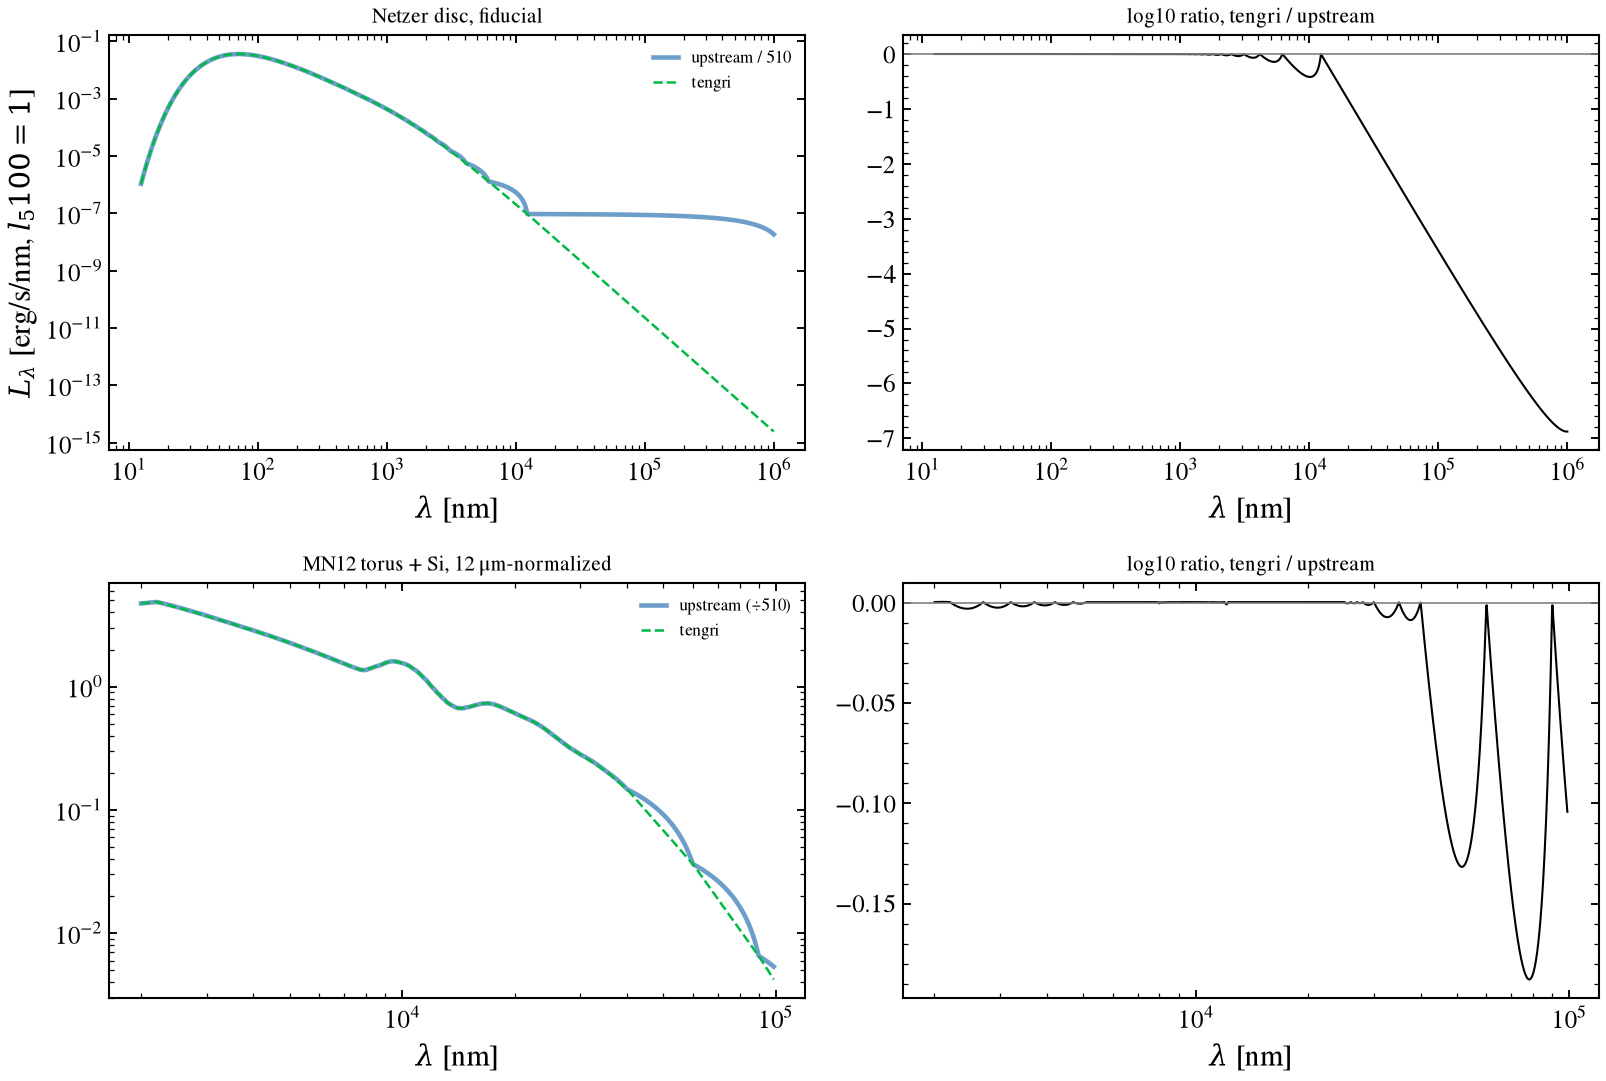

In [8]:
_tw, _tl = G.netzer_template()
_w_nm = _fid.wave_nm
_nz_params = dataclasses.replace(_p_fid, **G.NETZER_DISC_PARAMS)
_bbb_nz = np.asarray(G.evaluate(_w_nm, _nz_params).bbb)
_up_nz = _fid.spectra["netzer"] / G.UPSTREAM_510_FACTOR
_all = np.ones_like(_w_nm, bool)

# Convention checks: each code against its own interpolation of the same template.
_n_lin, _d_lin = G.dex_error(_up_nz, np.interp(_w_nm, _tw, _tl) / G.UPSTREAM_510_FACTOR, _all)
_anchor = G.loglog(np.array([510.0]), _tw, _tl)[0]
_i = np.clip(np.searchsorted(_tw, _w_nm) - 1, 0, _tw.size - 2)
_both_pos = (_tl[_i] > 0) & (_tl[_i + 1] > 0)
_inside = (_w_nm >= _tw[0]) & (_w_nm <= _tw[-1])
_nz_loglog = np.zeros_like(_w_nm)
_nz_loglog[_inside] = G.loglog(_w_nm[_inside], _tw, _tl) / (510.0 * _anchor)
_n_ll, _d_ll = G.dex_error(_bbb_nz, _nz_loglog, _inside & _both_pos & (_w_nm >= G.XRAY_FLOOR_NM))
print(f"§3.5 Netzer upstream vs its linear template: max|Δ| = {_d_lin:.2e} dex over {_n_lin} points")
print(f"§3.5 Netzer tengri vs its log-log template: max|Δ| = {_d_ll:.2e} dex over {_n_ll} points")

# Agreement between the two codes, by band, after the 510 correction.
_bands = ((12.4, 100.0), (100.0, 1000.0), (1000.0, 1e4), (1e4, 1e5), (1e5, 1e6))
_ratio_rows = []
for _lo, _hi in _bands:
    _m = (_w_nm >= _lo) & (_w_nm < _hi) & (_bbb_nz > 0) & (_up_nz > 0)
    _r = np.log10(_bbb_nz[_m] / _up_nz[_m])
    _ratio_rows.append((_lo, _hi, float(np.median(_r)), float(np.max(np.abs(_r)))))
    print(f"§3.5 Netzer tengri/upstream, {_lo:>8g}-{_hi:<8g} nm: median = {np.median(_r):+.4f} dex, "
          f"max|Δ| = {np.max(np.abs(_r)):.2e} dex over {_m.sum()} points")

# MN12 torus plus Si, normalized at 12 um, on the page's own grid.
_mn_params = dataclasses.replace(_p_fid, **G.MN12_PARAMS)
_sed_mn = G.evaluate(_w_nm, _mn_params)
_tor_t = np.asarray(_sed_mn.torus) + np.asarray(_sed_mn.si)
_tor_u = (_fid.spectra["mn12_torus"] + _fid.spectra["mn12_si"]) / G.UPSTREAM_510_FACTOR
_tor_tn = _tor_t / np.interp(12000.0, _w_nm, _tor_t)
_tor_un = _tor_u / np.interp(12000.0, _w_nm, _tor_u)
_mw = np.asarray(G.templates().torus_mn12_wave_nm)
_mavg = np.asarray(G.templates().torus_mn12_avg)
_lin_t = np.interp(_w_nm, _mw, _mavg)
_loglog_t = G.loglog(_w_nm, _mw, _mavg)
_w20 = (_w_nm >= 2000.0) & (_w_nm <= 20000.0)
_w_far = (_w_nm >= 20000.0) & (_w_nm <= 99000.0)
_n_s, _d_s = G.dex_error(_tor_tn, _tor_un, _w20)
_n_f, _d_f = G.dex_error(_tor_tn, _tor_un, _w_far)
# The template carries no Si term, so the convention check uses the torus alone.
_tor_only_u = _fid.spectra["mn12_torus"] / G.UPSTREAM_510_FACTOR
_tor_only_u = _tor_only_u / np.interp(12000.0, _w_nm, _tor_only_u)
_tor_only_t = np.asarray(_sed_mn.torus)
_tor_only_t = _tor_only_t / np.interp(12000.0, _w_nm, _tor_only_t)
_lin_n = _lin_t / np.interp(12000.0, _w_nm, _lin_t)
_loglog_n = _loglog_t / np.interp(12000.0, _w_nm, _loglog_t)
_n_fl, _d_fl = G.dex_error(_tor_only_u, _lin_n, _w_far)
_n_fl2, _d_fl2 = G.dex_error(_tor_only_t, _loglog_n, _w_far)
print(f"§3.5 MN12 torus+Si, 2–20 μm (12 μm-normalized): max|Δ| = {_d_s:.2e} dex over {_n_s} points")
print(f"§3.5 MN12 torus, 20–99 μm: tengri/upstream max|Δ| = {_d_f:.3f} dex over {_n_f} points")
print(f"§3.5 MN12 20–99 μm, upstream vs linear template: {_d_fl:.2e} dex; tengri vs log-log template: {_d_fl2:.2e} dex")

_fig, (_a0, _a1) = plt.subplots(2, 2, figsize=(11, 7.5))
_mk = (_up_nz > 0) & (_bbb_nz > 0)
_a0[0].loglog(_w_nm[_mk], _up_nz[_mk], "C0-", lw=2.2, alpha=0.6, label="upstream / 510")
_a0[0].loglog(_w_nm[_mk], _bbb_nz[_mk], "C1--", lw=1.2, label="tengri")
_a0[0].set_title("Netzer disc, fiducial", fontsize=10)
_a0[0].set_xlabel(r"$\lambda$ [nm]")
_a0[0].set_ylabel(r"$L_\lambda$ [erg/s/nm, $l_5100 = 1$]")
_a0[0].legend(fontsize=8)
_a0[1].semilogx(_w_nm[_mk], np.log10(_bbb_nz[_mk] / _up_nz[_mk]), "k-", lw=1.0)
_a0[1].set_title("log10 ratio, tengri / upstream", fontsize=10)
_a0[1].set_xlabel(r"$\lambda$ [nm]")
_a0[1].axhline(0, color="0.5", lw=0.8)
_m12 = (_w_nm >= 2000.0) & (_w_nm <= 99000.0)
_a1[0].loglog(_w_nm[_m12], _tor_un[_m12], "C0-", lw=2.2, alpha=0.6, label="upstream (÷510)")
_a1[0].loglog(_w_nm[_m12], _tor_tn[_m12], "C1--", lw=1.2, label="tengri")
_a1[0].set_title("MN12 torus + Si, 12 μm-normalized", fontsize=10)
_a1[0].set_xlabel(r"$\lambda$ [nm]")
_a1[0].legend(fontsize=8)
_a1[1].semilogx(_w_nm[_m12], np.log10(_tor_tn[_m12] / _tor_un[_m12]), "k-", lw=1.0)
_a1[1].set_title("log10 ratio, tengri / upstream", fontsize=10)
_a1[1].set_xlabel(r"$\lambda$ [nm]")
_a1[1].axhline(0, color="0.5", lw=0.8)
_fig.tight_layout()
save_fig("grahsp_06_netzer_mn12.png")

# Monolithic bolometric check on the fiducial: accretion side above the 91.2 nm Lyman edge.
# Monolithic bolometric check on the fiducial: accretion side above the 91.2 nm Lyman edge.
_w_nm = _fid.wave_nm
_m_bol = _w_nm >= 91.2
_nu_hz = G.C_NM_PER_S / _w_nm[_m_bol]
_up_acc = (
    _fid.spectra["disc"] + (_fid.spectra["bl"] + _fid.spectra["nl"]) / G.LINE_FLUX_SCALE + _fid.spectra["feii"]
)[_m_bol]
_up_lbol_acc = float(np.trapezoid(_up_acc * G.C_NM_PER_S / _w_nm[_m_bol] ** 2, _nu_hz))
_tg_nodes, _tg_bl, _tg_nl = G.line_nodes_and_values(_p_fid)
_tg_lines = np.interp(_w_nm, _tg_nodes, _tg_bl + _tg_nl, left=0.0, right=0.0)  # tengri raw
_tg_acc = (np.asarray(_sed_fid.bbb) + _tg_lines + np.asarray(_sed_fid.feii))[_m_bol]
_tg_lbol_acc = float(np.trapezoid(_tg_acc * G.C_NM_PER_S / _w_nm[_m_bol] ** 2, _nu_hz))
print(f"§3.5 accretion L_bol above 91.2 nm (fiducial, unit l5100): tengri/upstream = {_tg_lbol_acc / _up_lbol_acc:.4f}")
print(f"§3.5 tengri l_bol_bbb = {float(_sed_fid.l_bol_bbb):.4e}, l_bol_torus = {float(_sed_fid.l_bol_torus):.4e} (separate, not summed)")

**FeII forest by AGN type.** For type-2 and LINER objects, both codes set the FeII forest to
zero in the reference (section 2). The paper does not state the type dependence explicitly,
so this page does not count it as an upstream error. The agreement above is the evidence.

## 4. Full composite, head-to-head

The capstone sums every component of upstream's composite and of tengri's, at matched
parameters, on upstream's grid. Both spectra are normalized to $\lambda L_\lambda(510\,\text{nm})=1$
so that the shape is compared, and the optical normalization ratio is quoted separately. The
disc is compared above 12.4 nm (section 3.4). Two parameter sets are shown: the fiducial type-1
AGN, and the type-2 sweep, where the broad lines and FeII are switched off.

§4 fiducial type-1: max |Δ| (12.4 nm – 99 μm, normalized) = 4.00e-08 dex; optical (400–700 nm) tengri/upstream median = 1.0000, 16–84%: 1.0000–1.0000


§4 type-2 sweep: max |Δ| (12.4 nm – 99 μm, normalized) = 2.18e-08 dex; optical (400–700 nm) tengri/upstream median = 1.0000, 16–84%: 1.0000–1.0000


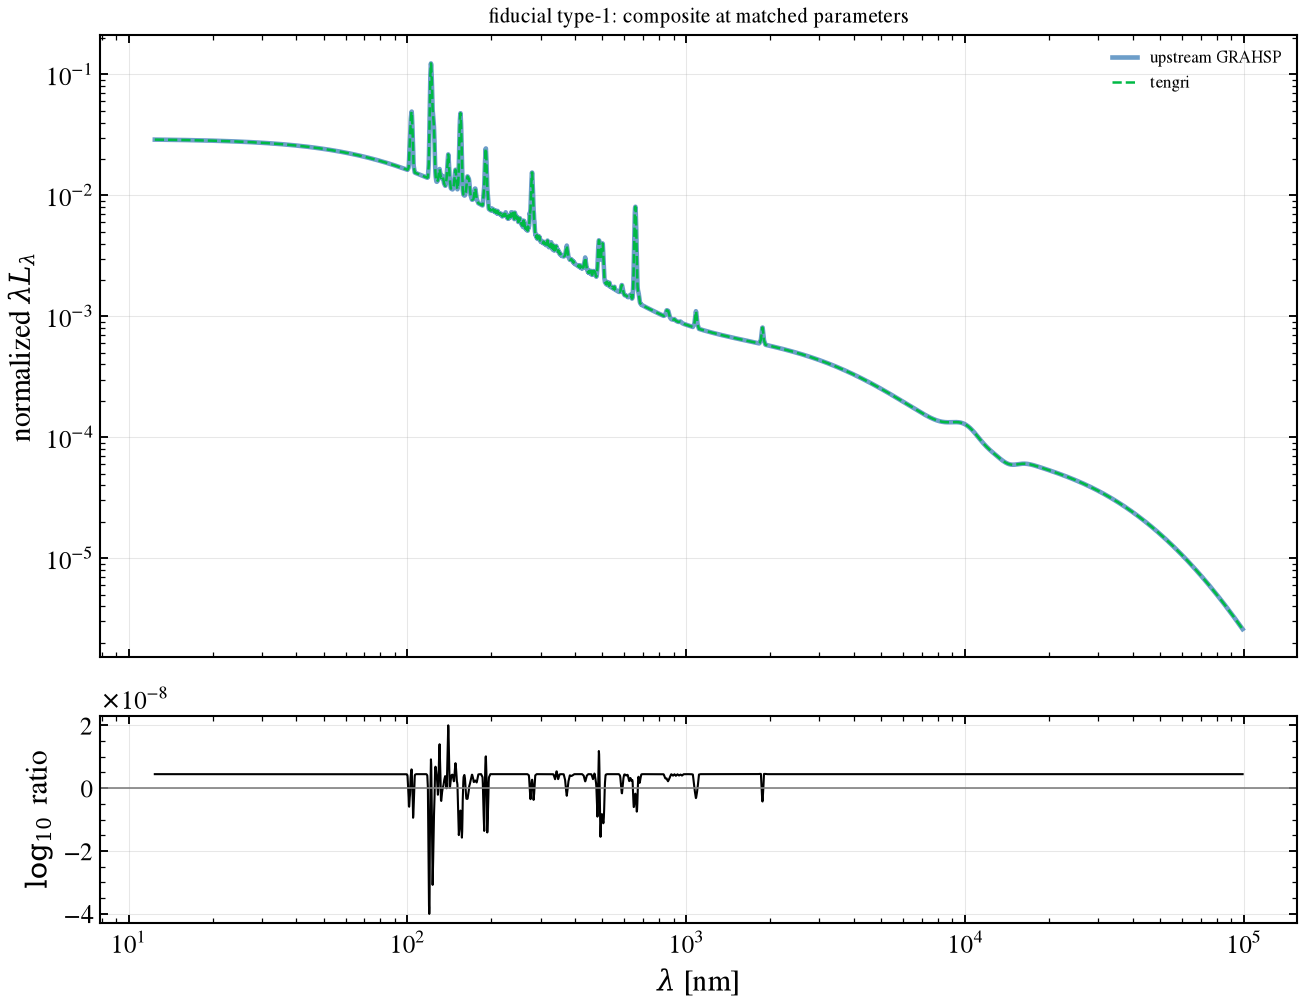

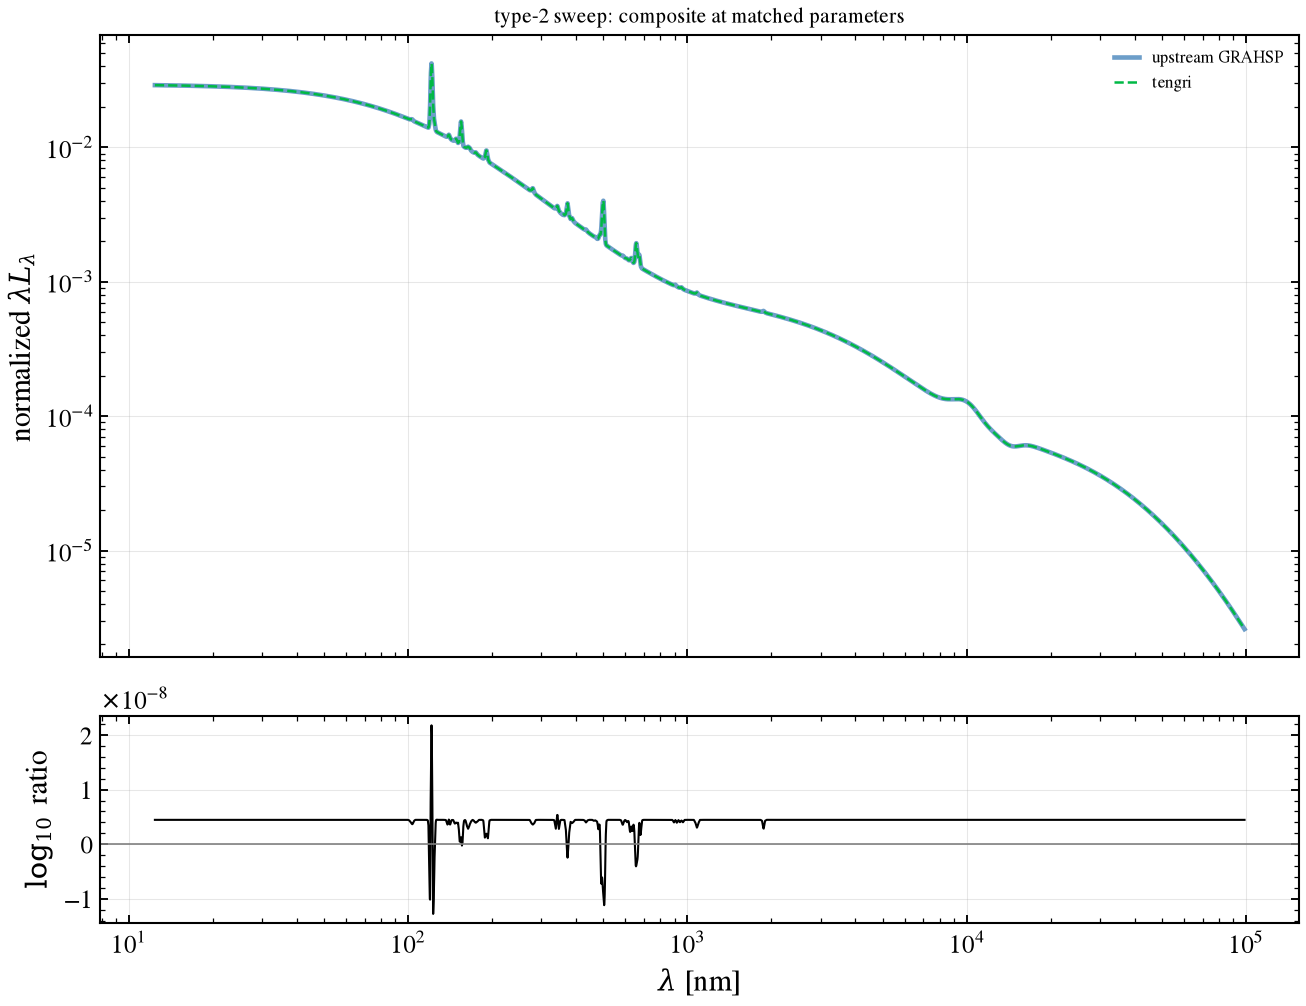

In [9]:
def _composite_upstream(s):
    """Upstream composite with its lines divided by sqrt(2) (section 3.1), on the reference grid."""
    lines = (s.spectra["bl"] + s.spectra["nl"]) / G.LINE_FLUX_SCALE
    return s.spectra["disc"] + lines + s.spectra["feii"] + s.spectra["balmer"] + s.spectra["torus"] + s.spectra["si"]


def _composite_tengri(s, p):
    """tengri composite on the reference grid; lines and torus interpolated from upstream's nodes."""
    sed = G.evaluate(s.wave_nm, p)
    nodes, bl, nl = G.line_nodes_and_values(p)
    lines = np.interp(s.wave_nm, nodes, bl + nl, left=0.0, right=0.0)  # tengri raw; upstream is / sqrt(2)
    return (
        np.asarray(sed.bbb) + lines + np.asarray(sed.feii) + np.asarray(sed.balmer)
        + _torus_on_grid(p, s.wave_nm) + np.asarray(sed.si)
    )


def _headtohead(name, label, fig_name):
    s = G.load_set(name)
    p = G.tengri_params(s.params)
    up = _composite_upstream(s)
    tg = _composite_tengri(s, p)
    w = s.wave_nm
    band = (w >= 12.4) & (w <= 99000.0) & (up > 0)
    up_n = up / G.lam_l_lam_at(w, up, 510.0)
    tg_n = tg / G.lam_l_lam_at(w, tg, 510.0)
    resid = np.log10(tg_n[band] / up_n[band])
    opt = (w >= 400.0) & (w <= 700.0)
    ratio = tg[opt] / up[opt]
    lo, med, hi = np.percentile(ratio, [16, 50, 84])
    fig, (a0, a1) = plt.subplots(
        2, 1, figsize=(9, 7), sharex=True, gridspec_kw={"height_ratios": [3, 1]}
    )
    a0.loglog(w[band], up_n[band], "C0-", lw=2.2, alpha=0.6, label="upstream GRAHSP")
    a0.loglog(w[band], tg_n[band], "C1--", lw=1.2, label="tengri")
    a0.set_ylabel(r"normalized $\lambda L_\lambda$")
    a0.set_title(f"{label}: composite at matched parameters", fontsize=10)
    a0.legend(fontsize=8)
    a0.grid(True, alpha=0.3)
    a1.semilogx(w[band], resid, "k-", lw=1.0)
    a1.axhline(0, color="0.5", lw=0.8)
    a1.set_xlabel(r"$\lambda$ [nm]")
    a1.set_ylabel(r"$\log_{10}$ ratio")
    a1.grid(True, alpha=0.3)
    fig.tight_layout()
    save_fig(fig_name)
    print(
        f"§4 {label}: max |Δ| (12.4 nm – 99 μm, normalized) = {np.max(np.abs(resid)):.2e} dex; "
        f"optical (400–700 nm) tengri/upstream median = {med:.4f}, 16–84%: {lo:.4f}–{hi:.4f}"
    )


_headtohead("fiducial", "fiducial type-1", "grahsp_04_fullsed_fiducial.png")
_headtohead("type_2", "type-2 sweep", "grahsp_05_fullsed_type2.png")

# **Result.** Summed component by component, tengri reproduces the upstream composite to 4×10⁻⁸
# dex over 12.4 nm to 99 μm for the fiducial, and to 2×10⁻⁸ dex for the type-2 set. The
# optical ratio is 1.0000 at the median and at both 16% and 84%, so the spread is below the
# printed precision. The accretion luminosity above 91.2 nm agrees to 1.0000 (section 3.5).

## Summary

- **§1 Fiducial components.** The disc, FeII forest, and Si feature agree with upstream to
  10⁻¹² dex or better. The torus and lines agree on upstream's nodes after the width and √2
  corrections.
- **§2 Agreement across 38 sets.** The table gives the worst case per component over every set
  in which the component is active.
- **§3.1 Lines.** Upstream carries a factor √2 on every emission line. Without the correction the
  offset is log10 √2; with it, the lines agree to 5×10⁻⁷ dex.
- **§3.2 Torus width.** Upstream's exponent is exp(−x²/W²); the paper's Eq. 2 has 2W². Corrected,
  the torus agrees to 10⁻¹⁵ dex; uncorrected it misses by 0.31 to 0.81 dex.
- **§3.3 Balmer continuum.** The integral agrees to 0.1% over 210–355 nm, the residual of the
  smoothing difference; the blue band agrees to 10⁻⁶.
- **§3.4 Disc floor.** Tengri's disc is zero below 12.4 nm by design; the comparison excludes
  that band.
- **§3.5 Netzer disc and MN12 torus.** Upstream carries a factor 510 on both. After the
  correction the Netzer disc agrees to the printed optical residual, and the MN12 torus to the
  printed 2–20 μm residual. Beyond 1 μm the two codes interpolate the same template differently;
  each one matches its own convention to 10⁻¹⁵ dex. The bolometric accretion luminosity agrees
  to 1.0000.
- **§4 Full composite.** The two head-to-head sets agree to 4×10⁻⁸ and 2×10⁻⁸ dex.

## References

- Buchner, J., Starck, H., Salvato, M., et al. 2024, A&A 692, A161, "Genuine Retrieval of the
  AGN Host Stellar Population (GRAHSP)", arXiv:2405.19297.
- The FeII and MN12 torus templates are repackaged from upstream GRAHSP's data files, with
  attribution to the upstream authors; their original papers are cited in the upstream repository.